# 01 — Data Exploration

Exploratory look at the three processed datasets (UCI-HAR, WISDM, PAMAP2)
before any model training. Run **after** `python -m src.preprocessing`
has populated `data/processed/*/`.

Covers:
1. Class distribution per dataset (raw imbalance check)
2. Subject distribution (window count per subject — relevant for LOSO fold sizing)
3. Native config sanity check (sampling rate / window length / channel count)
4. Sample raw signal plots per activity
5. Per-channel value ranges (sanity check before normalization)
6. Official vs. LOSO split shapes

Findings from this notebook should be summarized back into
`docs/research_gap_notes.md` if anything changes the preprocessing assumptions
(e.g. unexpected class imbalance, subject count mismatch, sensor units off).


## Setup

In [2]:
import sys
sys.path.append("..")  # so `src.*` imports work from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.preprocessing import PROCESSED_DIR, NATIVE_CONFIGS
from src.data_loader import _load_processed, get_official_split, get_loso_folds, LOSO_N_FOLDS

plt.rcParams["figure.figsize"] = (10, 4)

DATASETS = ["ucihar", "wisdm", "pamap2"]


## 1. Load processed arrays

Loads the raw `(X, y, subject)` arrays saved by `preprocessing.py`
(pre-normalization — normalization happens per-split in `data_loader.py`,
not here).

In [8]:
data = {}
for ds in DATASETS:
    try:
        X, y, subject, official_split = _load_processed(ds)
        data[ds] = dict(X=X, y=y, subject=subject, official_split=official_split)
        print(f"{ds:8s}  X={X.shape}  y={y.shape}  "
              f"n_subjects={len(np.unique(subject))}  "
              f"official_split={'yes' if official_split is not None else 'no (seeded 80/20 fallback)'}")
    except FileNotFoundError as e:
        print(f"{ds:8s}  NOT FOUND — run `python -m src.preprocessing` first ({e})")


ucihar    X=(10299, 128, 6)  y=(10299,)  n_subjects=30  official_split=yes
wisdm     X=(43101, 51, 3)  y=(43101,)  n_subjects=36  official_split=no (seeded 80/20 fallback)
pamap2    X=(14968, 256, 6)  y=(14968,)  n_subjects=9  official_split=no (seeded 80/20 fallback)


## 2. Native config sanity check

Confirms sampling rate / window size / step match what's assumed in
`preprocessing.py`'s `NATIVE_CONFIGS`, and that the channel count in the
loaded arrays matches expectations (6 for UCI-HAR/WISDM/PAMAP2-hand in the
current default config).

In [9]:
for ds in DATASETS:
    if ds not in data:
        continue
    cfg = NATIVE_CONFIGS[ds]
    n_channels = data[ds]["X"].shape[-1]
    window_len = data[ds]["X"].shape[1]
    print(f"{ds:8s}  configured window_samples={cfg['window_samples']:>4}  "
          f"actual window_len={window_len:>4}  "
          f"sampling_rate={cfg['sampling_rate']:>4}Hz  "
          f"n_channels={n_channels}")
    assert window_len == cfg["window_samples"], f"{ds}: window length mismatch!"


ucihar    configured window_samples= 128  actual window_len= 128  sampling_rate=  50Hz  n_channels=6
wisdm     configured window_samples=  51  actual window_len=  51  sampling_rate=  20Hz  n_channels=3
pamap2    configured window_samples= 256  actual window_len= 256  sampling_rate= 100Hz  n_channels=6


## 3. Class distribution

Raw activity label imbalance per dataset. Important context for interpreting
accuracy vs. macro-F1 later — a model can post a misleadingly high accuracy
on an imbalanced dataset while doing poorly on minority activities.

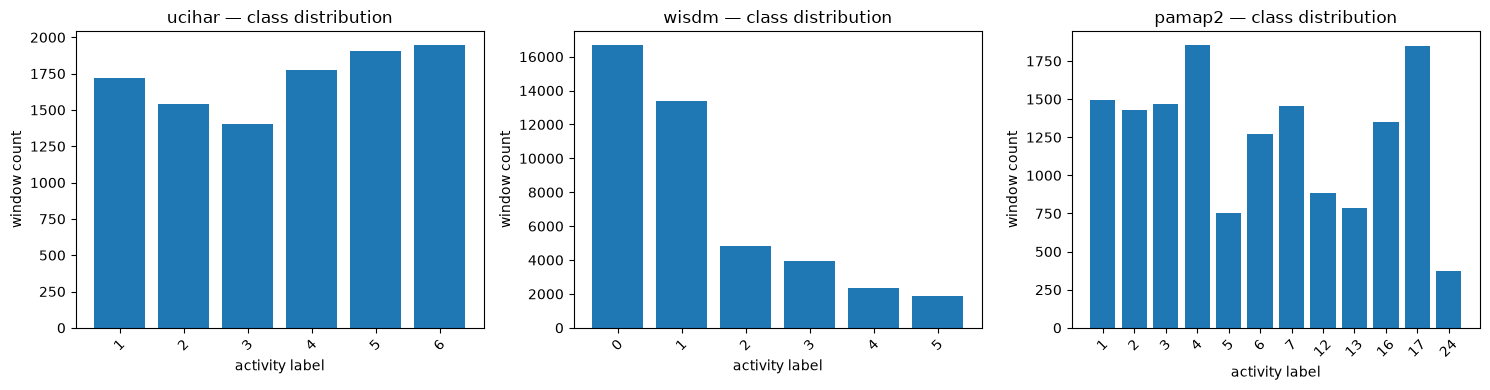

In [10]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(15, 4))
for ax, ds in zip(axes, DATASETS):
    if ds not in data:
        ax.set_title(f"{ds} (not found)")
        continue
    labels, counts = np.unique(data[ds]["y"], return_counts=True)
    ax.bar(labels.astype(str), counts)
    ax.set_title(f"{ds} — class distribution")
    ax.set_xlabel("activity label")
    ax.set_ylabel("window count")
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


## 4. Subject distribution

Window count per subject. Uneven contribution per subject matters for LOSO:
a fold that happens to hold out a subject with unusually many/few windows
will have a differently-sized test set than other folds. Worth knowing
before interpreting per-fold variance in the significance tests later.

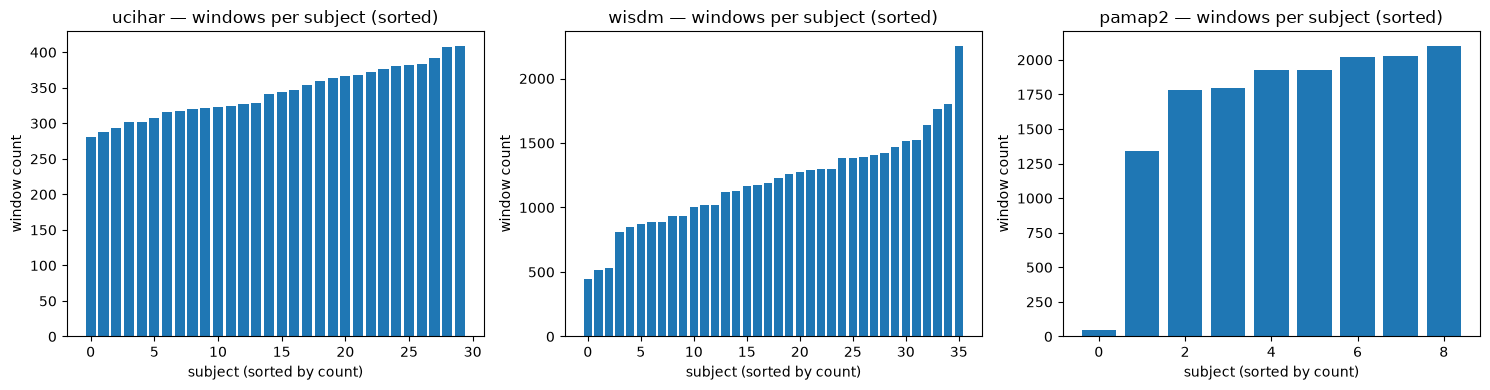

ucihar    30 subjects -> 6 LOSO folds (~5.0 subjects held out per fold)
wisdm     36 subjects -> 6 LOSO folds (~6.0 subjects held out per fold)
pamap2    9 subjects -> 9 LOSO folds (~1.0 subjects held out per fold)


In [11]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(15, 4))
for ax, ds in zip(axes, DATASETS):
    if ds not in data:
        ax.set_title(f"{ds} (not found)")
        continue
    subj, counts = np.unique(data[ds]["subject"], return_counts=True)
    ax.bar(range(len(subj)), sorted(counts))
    ax.set_title(f"{ds} — windows per subject (sorted)")
    ax.set_xlabel("subject (sorted by count)")
    ax.set_ylabel("window count")
plt.tight_layout()
plt.show()

for ds in DATASETS:
    if ds not in data:
        continue
    n_folds = LOSO_N_FOLDS[ds]
    n_subj = len(np.unique(data[ds]["subject"]))
    print(f"{ds:8s}  {n_subj} subjects -> {n_folds} LOSO folds "
          f"(~{n_subj / n_folds:.1f} subjects held out per fold)")


## 5. Sample raw signal plots

One example window per activity, per dataset, first channel only (to eyeball
signal shape/scale/noise — not a substitute for per-channel stats in §6).

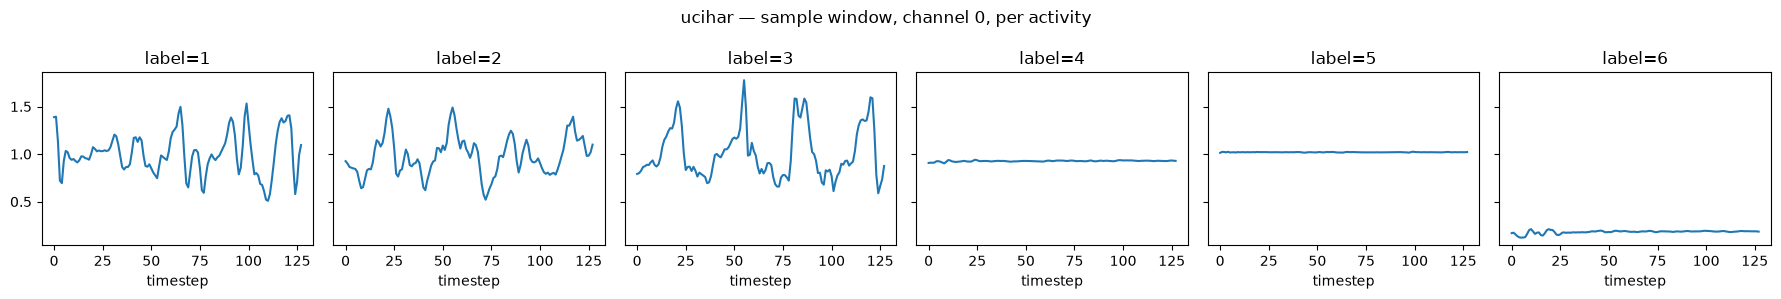

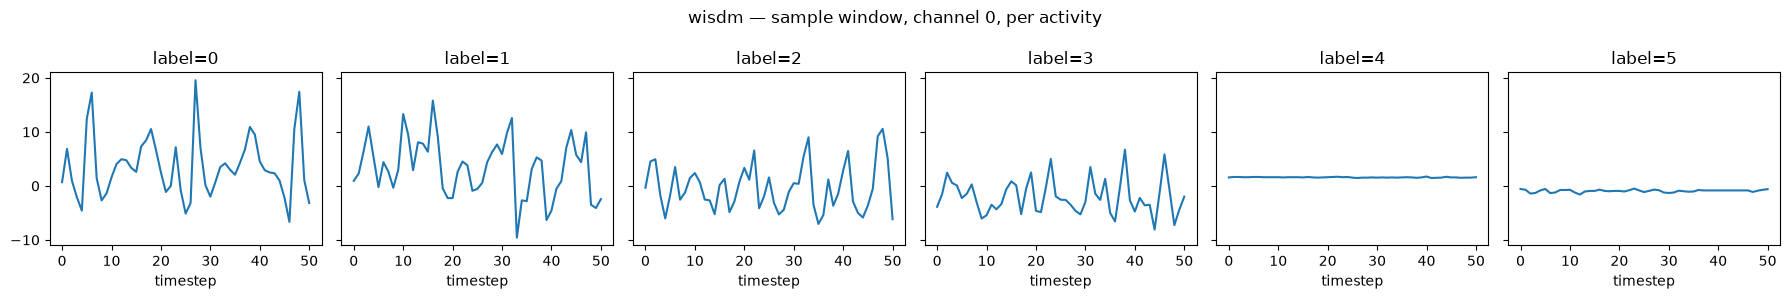

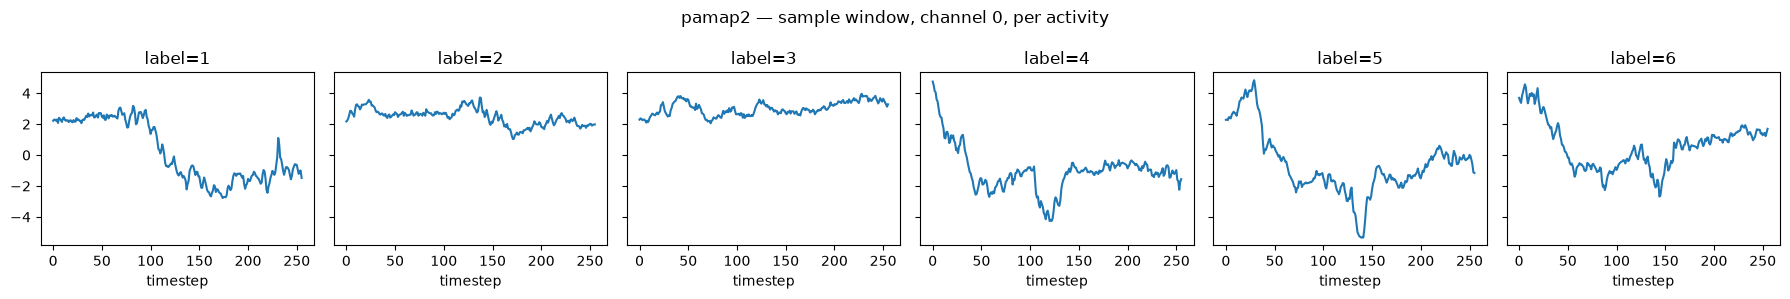

In [12]:
def plot_sample_windows(ds_name, X, y, n_examples=6):
    unique_labels = np.unique(y)[:n_examples]
    fig, axes = plt.subplots(1, len(unique_labels), figsize=(3 * len(unique_labels), 3), sharey=True)
    if len(unique_labels) == 1:
        axes = [axes]
    for ax, lbl in zip(axes, unique_labels):
        idx = np.where(y == lbl)[0][0]
        ax.plot(X[idx, :, 0])
        ax.set_title(f"label={lbl}")
        ax.set_xlabel("timestep")
    fig.suptitle(f"{ds_name} — sample window, channel 0, per activity")
    plt.tight_layout()
    plt.show()

for ds in DATASETS:
    if ds in data:
        plot_sample_windows(ds, data[ds]["X"], data[ds]["y"])


## 6. Per-channel value ranges (pre-normalization)

Sanity check on units (should look like g / deg-per-s scale, not raw ADC
counts) and confirms nothing is NaN/inf before it hits the normalization
step in `data_loader.py`.

In [13]:
for ds in DATASETS:
    if ds not in data:
        continue
    X = data[ds]["X"]
    print(f"\n{ds} — per-channel stats (pre-normalization):")
    stats = pd.DataFrame({
        "channel": range(X.shape[-1]),
        "mean": X.mean(axis=(0, 1)),
        "std": X.std(axis=(0, 1)),
        "min": X.min(axis=(0, 1)),
        "max": X.max(axis=(0, 1)),
        "has_nan": np.isnan(X).any(axis=(0, 1)),
    })
    display(stats)



ucihar — per-channel stats (pre-normalization):


,channel,mean,std,min,max,has_nan
0,0,0.808330,0.411991,-0.466556,2.197618,False
1,1,0.021772,0.397284,-1.588211,1.217350,False
2,2,0.084831,0.344254,-1.639609,1.281363,False
3,3,-0.003411,0.403942,-4.733656,4.155473,False
4,4,-0.000172,0.370480,-5.974330,5.746062,False
5,5,0.000896,0.253952,-2.763014,2.365982,False



wisdm — per-channel stats (pre-normalization):


,channel,mean,std,min,max,has_nan
0,0,0.663938,6.887701,-19.61,19.95,False
1,1,7.244081,6.750474,-19.61,20.04,False
2,2,0.391965,4.764673,-19.80,19.61,False



pamap2 — per-channel stats (pre-normalization):


,channel,mean,std,min,max,has_nan
0,0,-4.966576,6.254452,-145.3670,62.8596,False
1,1,3.573334,6.917483,-104.3010,155.6990,False
2,2,3.613952,3.963055,-101.4520,157.7600,False
3,3,0.001625,1.339725,-28.1354,26.4158,False
4,4,0.039780,0.961481,-17.8495,23.0779,False
5,5,-0.004030,1.609133,-14.2647,14.3384,False


## 7. Split shape check (official + LOSO)

Confirms `data_loader.py`'s two split modes both produce sane, non-empty,
correctly-normalized train/test partitions before any model touches them.

In [14]:
for ds in DATASETS:
    if ds not in data:
        continue
    try:
        X_tr, y_tr, X_te, y_te = get_official_split(ds)
        print(f"{ds:8s} official split -> train {X_tr.shape} (mean~{X_tr.mean():.3f}), "
              f"test {X_te.shape}")

        fold_sizes = [(f["fold_id"], len(f["y_train"]), len(f["y_test"]))
                      for f in get_loso_folds(ds)]
        print(f"{ds:8s} LOSO folds -> " +
              ", ".join(f"fold{fid}: train={ntr} test={nte}" for fid, ntr, nte in fold_sizes))
    except FileNotFoundError as e:
        print(f"{ds:8s} skipped: {e}")


ucihar   official split -> train (7352, 128, 6) (mean~-0.000), test (2947, 128, 6)
ucihar   LOSO folds -> fold0: train=8518 test=1781, fold1: train=8578 test=1721, fold2: train=8661 test=1638, fold3: train=8575 test=1724, fold4: train=8451 test=1848, fold5: train=8712 test=1587
wisdm    official split -> train (33992, 51, 3) (mean~-0.000), test (9109, 51, 3)
wisdm    LOSO folds -> fold0: train=34876 test=8225, fold1: train=36658 test=6443, fold2: train=35540 test=7561, fold3: train=37071 test=6030, fold4: train=35990 test=7111, fold5: train=35370 test=7731
pamap2   official split -> train (10918, 256, 6) (mean~-0.000), test (4050, 256, 6)
pamap2   LOSO folds -> fold0: train=12948 test=2020, fold1: train=12938 test=2030, fold2: train=13042 test=1926, fold3: train=13043 test=1925, fold4: train=14920 test=48, fold5: train=13627 test=1341, fold6: train=12867 test=2101, fold7: train=13184 test=1784, fold8: train=13175 test=1793


## Notes / next steps

- [ ] Confirm class imbalance (§3) doesn't require class-weighted loss —
      decide before Week 4 baseline training.
- [ ] Confirm no dataset has a pathologically small LOSO fold (§4) that would
      make per-fold significance testing unstable.
- [ ] Flag here if any dataset's raw parsing (WISDM/PAMAP2 in particular)
      produced fewer windows or subjects than expected — cheaper to catch now
      than after Week 6 baselines are already trained on bad data.
